In [5]:
from pathlib import Path
from decimal import Decimal
import re

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Setup
# ------------------------------------------------------------

# The .npz files are inside:
# .../Revised_lr_variation/Comparison/2000 Epochs
DATA_DIR = Path('2000 Epochs')

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f'Data directory does not exist: {DATA_DIR.resolve()}'
    )

OUTPUT_DIR = DATA_DIR / 'actor_loss_figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Learning rates represented by:
#
# 0_000001 -> 0.000001
# 0_00001  -> 0.00001
# 0_0001   -> 0.0001
LEARNING_RATES = (
    '0.000001',
    '0.00001',
    '0.0001'
)

NODES = (
    45,
    55,
    65
)

COLORS = {
    '0.000001': 'navy',
    '0.00001': 'orange',
    '0.0001': 'crimson',
}

WINDOW = 10
SAVE_FIGURES = True


# ------------------------------------------------------------
# Figure appearance
# ------------------------------------------------------------

plt.rcParams.update({
    'font.family': 'DejaVu Serif',
    'font.size': 10,
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'axes.linewidth': 1.0,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})


# ------------------------------------------------------------
# Filename pattern
#
# Examples:
#
# ha2c_training_results_45 nodes_lr_0_000001.npz
# ha2c_training_results_45 nodes_lr_0_00001.npz
# ha2c_training_results_45 nodes_lr_0_0001.npz
# ------------------------------------------------------------

FILE_PATTERN = re.compile(
    r'(?P<nodes>\d+)[ _-]*nodes[ _-]*lr[_-]*(?P<lr>0[_.]\d+)\.npz$',
    re.IGNORECASE,
)


# ------------------------------------------------------------
# Actor-loss key pattern
#
# Examples:
#
# agent1_actor_loss_lr_0_00001
# agent2_actor_loss_lr_0_00001
# ------------------------------------------------------------

KEY_PATTERN = re.compile(
    r'agent(?P<agent>[12])_actor_loss_lr_(?P<lr>0[_.]\d+)',
    re.IGNORECASE,
)


def as_rate(text):
    """
    Convert:

        0_000001 -> Decimal('0.000001')
        0.000001 -> Decimal('0.000001')
    """

    return Decimal(
        str(text).replace('_', '.')
    )


# Precompute requested rates
EXPECTED_RATES = {
    as_rate(rate)
    for rate in LEARNING_RATES
}


# ------------------------------------------------------------
# Show files being detected
# ------------------------------------------------------------

source_files = sorted(
    DATA_DIR.glob('*.npz')
)

print(
    f'Data directory:\n{DATA_DIR.resolve()}'
)

print(
    f'\nFound {len(source_files)} NPZ files:\n'
)

for path in source_files:
    print(f'  {path.name}')


if not source_files:
    raise FileNotFoundError(
        f'No .npz files found in:\n'
        f'{DATA_DIR.resolve()}'
    )


# ------------------------------------------------------------
# 2. Read matching actor losses and average Agent 1 + Agent 2
# ------------------------------------------------------------

averaged_losses = {}

for path in source_files:

    # --------------------------------------------------------
    # Extract node count and LR from filename
    # --------------------------------------------------------

    match = FILE_PATTERN.search(
        path.name
    )

    if not match:
        print(
            f'Skipping filename that does not match pattern: '
            f'{path.name}'
        )
        continue

    nodes = int(
        match.group('nodes')
    )

    lr = as_rate(
        match.group('lr')
    )

    # --------------------------------------------------------
    # Only use desired node counts
    # --------------------------------------------------------

    if nodes not in NODES:
        print(
            f'Skipping unsupported node count: '
            f'{path.name}'
        )
        continue

    # --------------------------------------------------------
    # Only use desired learning rates
    # --------------------------------------------------------

    if lr not in EXPECTED_RATES:
        print(
            f'Skipping unsupported LR={lr}: '
            f'{path.name}'
        )
        continue

    # --------------------------------------------------------
    # Load archive
    # --------------------------------------------------------

    with np.load(
        path,
        allow_pickle=False
    ) as archive:

        agent_losses = {}

        # ----------------------------------------------------
        # Search for Agent 1 and Agent 2 actor losses
        # ----------------------------------------------------

        for key in archive.files:

            key_match = KEY_PATTERN.fullmatch(
                key
            )

            if not key_match:
                continue

            key_lr = as_rate(
                key_match.group('lr')
            )

            # Key must correspond to filename LR
            if key_lr != lr:
                continue

            agent = int(
                key_match.group('agent')
            )

            arr = np.asarray(
                archive[key],
                dtype=np.float64
            )

            if (
                arr.ndim != 1
                or arr.size == 0
            ):
                raise ValueError(
                    f'{path.name}: {key} must be '
                    f'a nonempty 1-D array; '
                    f'got shape {arr.shape}'
                )

            agent_losses[agent] = arr


    # --------------------------------------------------------
    # Make sure both Agent 1 and Agent 2 exist
    # --------------------------------------------------------

    if set(agent_losses) != {1, 2}:

        raise KeyError(
            f'\n{path.name}\n'
            f'Expected matching Agent 1 and Agent 2 '
            f'actor-loss keys for LR={lr}.\n'
            f'Found agents: {sorted(agent_losses)}'
        )


    # --------------------------------------------------------
    # Make sure arrays have equal lengths
    # --------------------------------------------------------

    if agent_losses[1].shape != agent_losses[2].shape:

        raise ValueError(
            f'{path.name}: Agent losses have unequal '
            f'episode counts: '
            f'{len(agent_losses[1])} and '
            f'{len(agent_losses[2])}.'
        )


    # --------------------------------------------------------
    # Check NaN / Inf
    # --------------------------------------------------------

    if not all(
        np.all(np.isfinite(arr))
        for arr in agent_losses.values()
    ):

        raise ValueError(
            f'{path.name}: actor-loss values contain '
            f'NaN or infinity.'
        )


    # --------------------------------------------------------
    # Store average Actor Loss
    # --------------------------------------------------------

    lookup = (
        nodes,
        lr
    )

    if lookup in averaged_losses:

        raise ValueError(
            f'Duplicate archive for '
            f'{nodes} nodes, LR={lr}:\n'
            f'{path.name}'
        )


    averaged_losses[lookup] = (
        agent_losses[1]
        +
        agent_losses[2]
    ) / 2.0


    print(
        f'Loaded: '
        f'{nodes} nodes | '
        f'LR={lr} | '
        f'{len(averaged_losses[lookup])} episodes'
    )


# ------------------------------------------------------------
# Check missing datasets
# ------------------------------------------------------------

missing = [
    (nodes, lr)
    for nodes in NODES
    for lr in LEARNING_RATES
    if (
        nodes,
        as_rate(lr)
    ) not in averaged_losses
]


if missing:

    print('\nSuccessfully loaded combinations:')

    for nodes, lr in sorted(
        averaged_losses
    ):
        print(
            f'  {nodes} nodes | LR={lr}'
        )

    raise FileNotFoundError(
        f'\nMissing expected node/LR data in:\n'
        f'{DATA_DIR.resolve()}\n\n'
        f'Missing combinations:\n'
        f'{missing}'
    )


# ------------------------------------------------------------
# 3. Moving-average helper
# ------------------------------------------------------------

def moving_average(values, window):

    if window == 1:
        return values.copy()

    if window > len(values):

        raise ValueError(
            f'WINDOW={window} exceeds '
            f'episode count {len(values)}.'
        )

    return np.convolve(
        values,
        np.ones(window) / window,
        mode='valid'
    )


# ------------------------------------------------------------
# 4. Plot helper
# ------------------------------------------------------------

def plot_node_lr_comparison(nodes):

    max_episodes = max(
        len(
            averaged_losses[
                (
                    nodes,
                    as_rate(lr)
                )
            ]
        )
        for lr in LEARNING_RATES
    )


    # ========================================================
    # Plot 1: RAW AVERAGE ACTOR LOSS
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(4.2, 3.2)
    )


    for lr_str in LEARNING_RATES:

        mean_loss = averaged_losses[
            (
                nodes,
                as_rate(lr_str)
            )
        ]

        episodes = np.arange(
            1,
            len(mean_loss) + 1
        )

        ax.plot(
            episodes,
            mean_loss,
            linestyle='--',
            linewidth=1.45,
            color=COLORS[lr_str],
            label=f'lr = {lr_str}'
        )


    ax.set_xlabel(
        'Episode',
        fontsize=11
    )

    ax.set_ylabel(
        'Average Actor Loss',
        fontsize=11
    )


    ax.set_xlim(
        0,
        max_episodes + 10
    )


    ax.set_xticks(
        np.arange(
            0,
            max_episodes + 1,
            500
        )
    )


    ax.grid(
        True,
        which='major',
        linestyle='--',
        color='gray',
        linewidth=0.75,
        alpha=0.6
    )


    ax.tick_params(
        axis='both',
        direction='in',
        length=5,
        width=1.0,
        labelsize=9
    )


    ax.legend(
        loc='best',
        fontsize=9,
        frameon=True,
        framealpha=0.95
    )


    fig.tight_layout()


    if SAVE_FIGURES:

        output_path = (
            OUTPUT_DIR
            / f'average_actor_loss_{nodes}_nodes_raw.png'
        )

        fig.savefig(
            output_path,
            dpi=600,
            bbox_inches='tight'
        )

        print(
            f'Saved: {output_path}'
        )


    plt.show()
    plt.close(fig)


    # ========================================================
    # Plot 2: MOVING-AVERAGE ACTOR LOSS
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(4.2, 3.5)
    )


    for lr_str in LEARNING_RATES:

        mean_loss = averaged_losses[
            (
                nodes,
                as_rate(lr_str)
            )
        ]


        smooth_loss = moving_average(
            mean_loss,
            WINDOW
        )


        # Align with original episode numbers
        episodes = np.arange(
            WINDOW,
            len(mean_loss) + 1
        )


        ax.plot(
            episodes,
            smooth_loss,
            linestyle='--',
            linewidth=1.45,
            color=COLORS[lr_str],
            label=f'LR = {lr_str}'
        )


    ax.set_xlabel(
        'Episode',
        fontsize=11
    )

    ax.set_ylabel(
        'Average Actor Loss',
        fontsize=11
    )


    ax.set_xlim(
        0,
        max_episodes + 10
    )


    ax.set_xticks(
        np.arange(
            0,
            max_episodes + 1,
            500
        )
    )


    ax.grid(
        True,
        which='major',
        linestyle='--',
        color='gray',
        linewidth=0.75,
        alpha=0.6
    )


    ax.tick_params(
        axis='both',
        direction='in',
        length=5,
        width=1.0,
        labelsize=9
    )


    ax.legend(
        loc='best',
        fontsize=9,
        frameon=True,
        framealpha=0.95
    )


    fig.tight_layout()


    if SAVE_FIGURES:

        output_path = (
            OUTPUT_DIR
            / (
                f'average_actor_loss_'
                f'{nodes}_nodes_'
                f'moving_average_{WINDOW}.png'
            )
        )

        fig.savefig(
            output_path,
            dpi=600,
            bbox_inches='tight'
        )

        print(
            f'Saved: {output_path}'
        )


    plt.show()
    plt.close(fig)


# # ------------------------------------------------------------
# # 5. Generate figures for all node counts
# # ------------------------------------------------------------

# for nodes in NODES:

#     print(
#         f'\n===== {nodes} Nodes ====='
#     )

#     plot_node_lr_comparison(
#         nodes
#     )


# print(
#     f'\nAll figures saved in:\n'
#     f'{OUTPUT_DIR.resolve()}'
# )

Data directory:
/home/cci/Downloads/Latest/Revised/Revised_lr_variation/Comparison/2000 Epochs

Found 9 NPZ files:

  ha2c_training_results_45 nodes_lr_0_000001.npz
  ha2c_training_results_45 nodes_lr_0_00001.npz
  ha2c_training_results_45 nodes_lr_0_0001.npz
  ha2c_training_results_55 nodes_lr_0_000001.npz
  ha2c_training_results_55 nodes_lr_0_00001.npz
  ha2c_training_results_55 nodes_lr_0_0001.npz
  ha2c_training_results_65 nodes_lr_0_000001.npz
  ha2c_training_results_65 nodes_lr_0_00001.npz
  ha2c_training_results_65 nodes_lr_0_0001.npz
Loaded: 45 nodes | LR=0.000001 | 2000 episodes
Loaded: 45 nodes | LR=0.00001 | 2000 episodes
Loaded: 45 nodes | LR=0.0001 | 2000 episodes
Loaded: 55 nodes | LR=0.000001 | 2000 episodes
Loaded: 55 nodes | LR=0.00001 | 2000 episodes
Loaded: 55 nodes | LR=0.0001 | 2000 episodes
Loaded: 65 nodes | LR=0.000001 | 2000 episodes
Loaded: 65 nodes | LR=0.00001 | 2000 episodes
Loaded: 65 nodes | LR=0.0001 | 2000 episodes


## Figure 1 — 45 nodes

Saved: 2000 Epochs/actor_loss_figures/average_actor_loss_45_nodes_raw.png


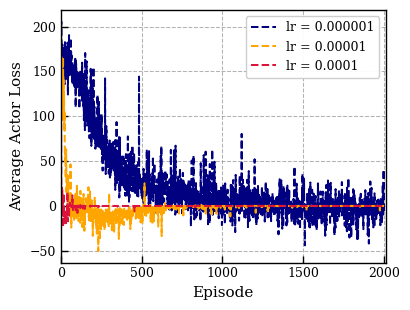

Saved: 2000 Epochs/actor_loss_figures/average_actor_loss_45_nodes_moving_average_10.png


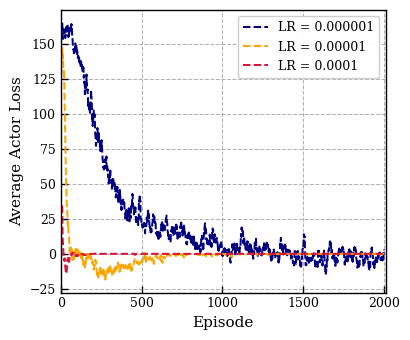

In [6]:
plot_node_lr_comparison(45)

## Figure 2 — 55 nodes

Saved: 2000 Epochs/actor_loss_figures/average_actor_loss_55_nodes_raw.png


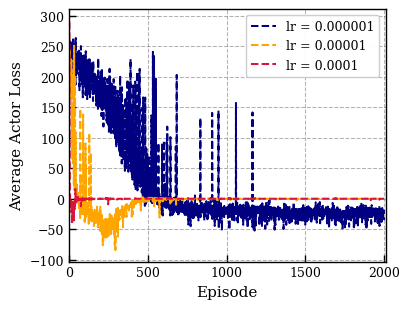

Saved: 2000 Epochs/actor_loss_figures/average_actor_loss_55_nodes_moving_average_10.png


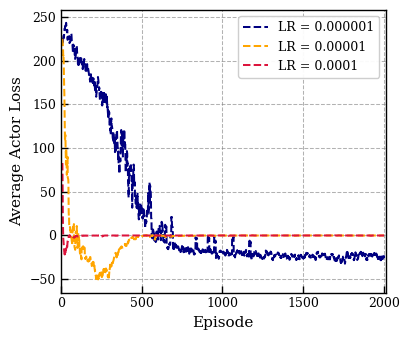

In [7]:
plot_node_lr_comparison(55)


## Figure 3 — 65 nodes

Saved: 2000 Epochs/actor_loss_figures/average_actor_loss_65_nodes_raw.png


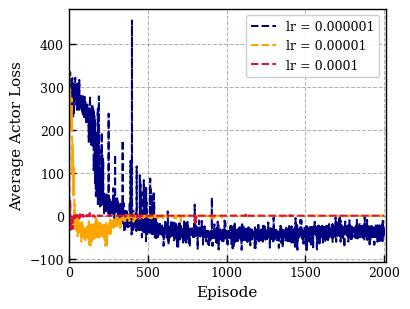

Saved: 2000 Epochs/actor_loss_figures/average_actor_loss_65_nodes_moving_average_10.png


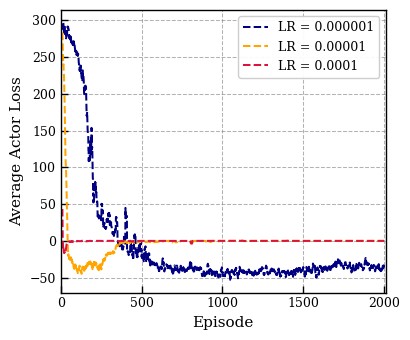

In [8]:
plot_node_lr_comparison(65)
